# Assessment on four real datasets

In [10]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src').exists())
sys.path.insert(0, str(REPO_ROOT / 'src')) if str(REPO_ROOT / 'src') not in sys.path else None

from data_preparation import (make_assessment_data, make_compas_workflow_data,
    make_law_school_workflow_data, prepare_compas,
    prepare_law_school, prepare_reddit, prepare_scut)
from estimate_effects import (diagnostic_table, effect_table,
    estimate_reference_specific_effects,
    plot_feature_group_curves, plot_real_data_effects, robustness_row)
from model_tuning import (load_tuned_config, make_estimator_options,
    make_robustness_options, reproducible_sample)

RANDOM_STATE = 1
DR_OPTIONS = {'n_splits': 5, 'random_state': RANDOM_STATE, 'propensity_clip': .01}
assessments = {}
TUNED_CONFIG_PATH = REPO_ROOT / 'results' / 'tuning' / 'best_nuisance_models.json'

def tuned_options(dataset):
    config = load_tuned_config(dataset, TUNED_CONFIG_PATH)
    outcome_name = config['outcome_model']['name']
    if outcome_name == 'linear_with_interactions' and config['outcome_type'] == 'binary':
        outcome_name = 'logistic_with_interactions'
    print(
        f"{dataset}: outcome={outcome_name}, "
        f"P(A|C)={config['propensity_models']['a_given_c']['name']}, "
        f"P(A|M,C)={config['propensity_models']['a_given_mc']['name']}, "
        f"reduction={config['reduction']['name']}"
    )
    return make_estimator_options(config)

In [11]:
def assess(dataset, data, mediators, confounders, outcome_label, **estimator_options):
    """Estimate and display observed-outcome effects."""
    result = estimate_reference_specific_effects(data, 'Y', 'A', mediators, confounders, **DR_OPTIONS, **estimator_options)
    assessments[dataset] = result
    effects = effect_table(result, dataset)
    diagnostics = diagnostic_table(result, dataset)
    display(effects.round(4))
    display(diagnostics.round(4))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    axes[0].barh(effects.effect, effects.estimate, xerr=1.96 * effects.standard_error, capsize=3)
    axes[0].axvline(0, color='black', linewidth=.8)
    axes[0].tick_params(axis='x', rotation=25)
    axes[0].set(ylabel=outcome_label, title=f'{dataset}: effects of observed Y')
    axes[1].bar(diagnostics.nested_mean, diagnostics.effective_sample_size)
    axes[1].set(ylabel='Effective sample size', title='Cross-reference weight stability')
    fig.tight_layout()
    plt.show()
    return result

## Law School

,rows
source_rows,22407
after_observed_race,22391
after_binary_bar_outcome,22391
complete_case_rows,20970


Law complete-case assessment cohort: 20,970


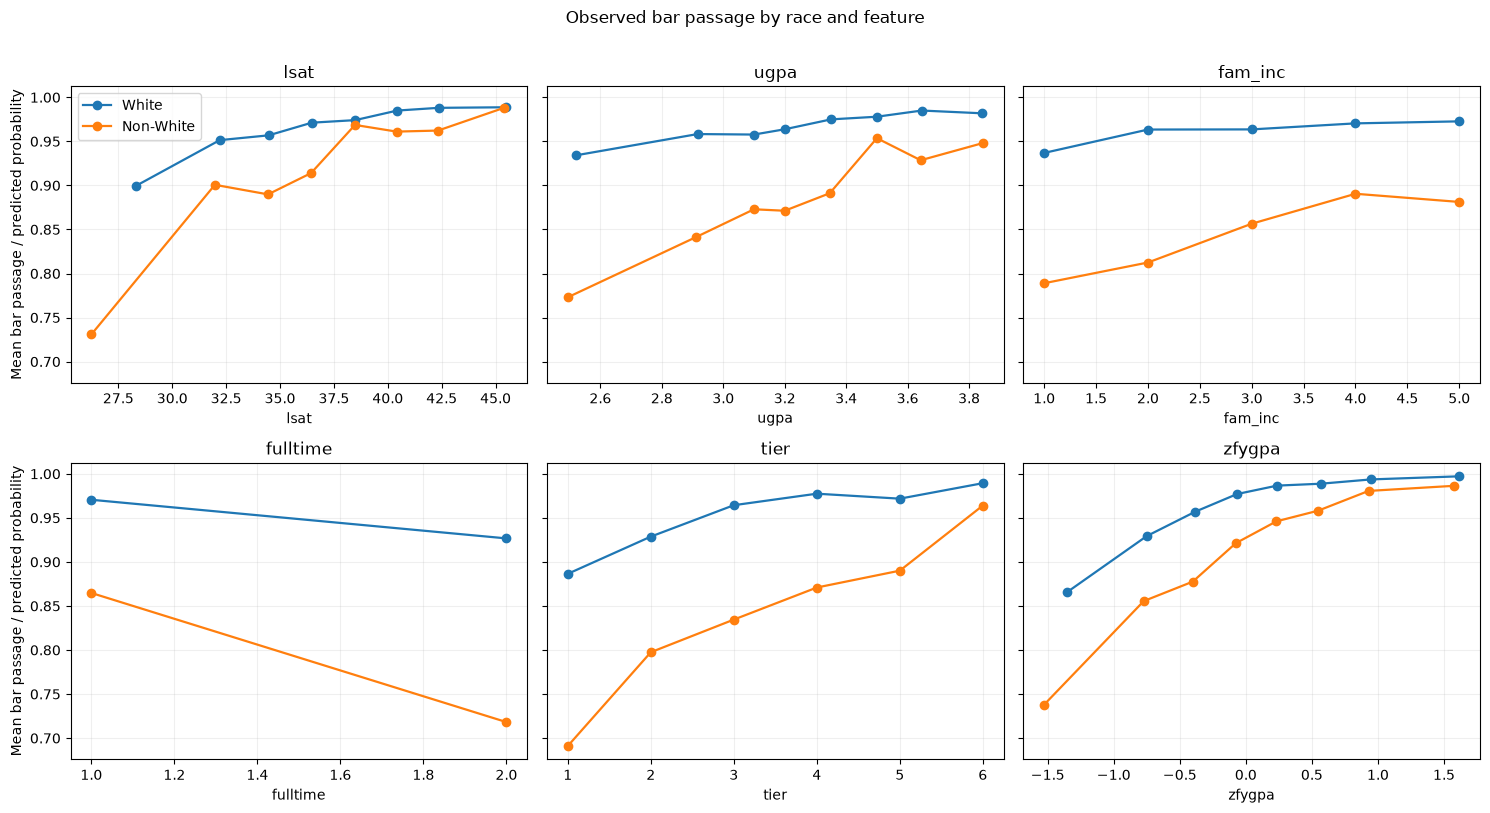

Law: outcome=logistic_with_interactions, P(A|C)=logistic, P(A|M,C)=logistic, reduction=none


,dataset,effect,estimate,standard_error,ci_low,ci_high
0,Law,nde_m0,-0.0173,0.0058,-0.0286,-0.0060
1,Law,nde_m1,-0.0378,0.0080,-0.0535,-0.0222
2,Law,nie_a0,-0.0746,0.0056,-0.0857,-0.0636
3,Law,nie_a1,-0.0951,0.0064,-0.1076,-0.0827
4,Law,interaction,-0.0205,0.0078,-0.0359,-0.0052
5,Law,total_effect,-0.1124,0.0063,-0.1248,-0.1001


,dataset,nested_mean,clip,propensity_c_min,propensity_c_max,propensity_mc_min,propensity_mc_max,fraction_propensity_c_clipped,fraction_propensity_mc_clipped,max_absolute_weight,...,propensity_c_roc_auc,propensity_c_brier_score,propensity_mc_roc_auc,propensity_mc_brier_score,outcome_f1,outcome_roc_auc,outcome_log_loss,outcome_brier_score,mediator_dimensions_by_fold,mediator_explained_variance_by_fold
0,Law,psi_00,0.01,0.066601,0.209415,0.01,0.99,0.0,0.034001,1.264886,...,0.54707,0.13545,0.810464,0.097016,0.97392,0.862318,0.152266,0.041163,"(6, 6, 6, 6, 6)","(nan, nan, nan, nan, nan)"
1,Law,psi_01,0.01,0.066601,0.209415,0.01,0.99,0.0,0.034001,273.646865,...,0.54707,0.13545,0.810464,0.097016,0.97392,0.862318,0.152266,0.041163,"(6, 6, 6, 6, 6)","(nan, nan, nan, nan, nan)"
2,Law,psi_10,0.01,0.066601,0.209415,0.01,0.99,0.0,0.034001,124.540047,...,0.54707,0.13545,0.810464,0.097016,0.97392,0.862318,0.152266,0.041163,"(6, 6, 6, 6, 6)","(nan, nan, nan, nan, nan)"
3,Law,psi_11,0.01,0.066601,0.209415,0.01,0.99,0.0,0.034001,13.578749,...,0.54707,0.13545,0.810464,0.097016,0.97392,0.862318,0.152266,0.041163,"(6, 6, 6, 6, 6)","(nan, nan, nan, nan, nan)"


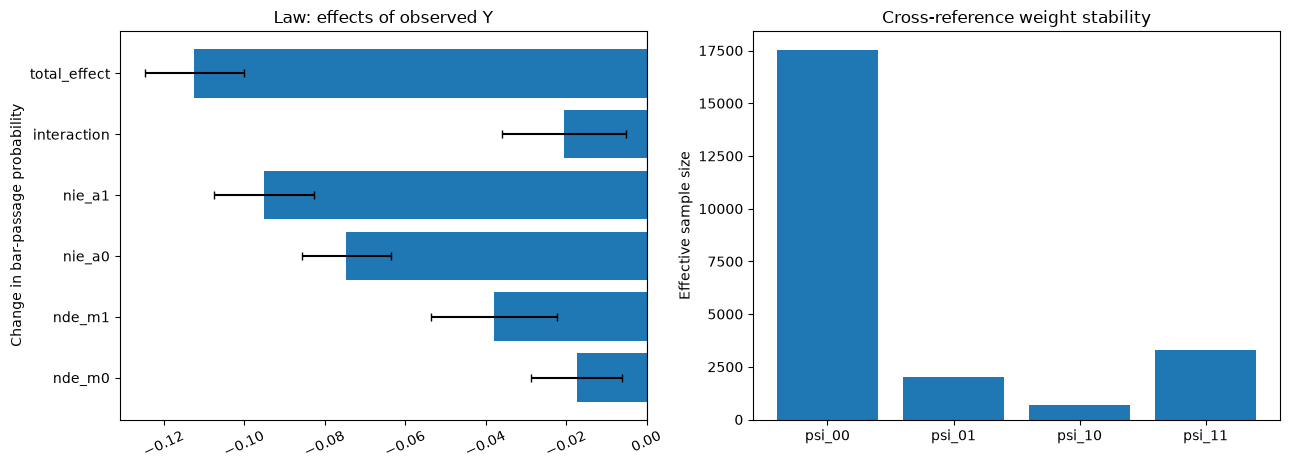

In [12]:
law_path = REPO_ROOT / 'data' / 'law_school' / 'bar_pass_prediction.csv'
law_dataset = prepare_law_school(law_path)
law = make_law_school_workflow_data(law_dataset)['assessment']
display(pd.Series(law_dataset['provenance']['cohort_audit']['counts'], name='rows').to_frame())
print(f"Law complete-case assessment cohort: {len(law['data']):,}")
observed_curve_frame = law['data'][['A', 'Y', *law['mediators']]].copy()
observed_curve_figure = plot_feature_group_curves(
    observed_curve_frame, outcome='Y',
    title='Observed bar passage by race and feature',
    features=list(law['mediators']),
    continuous_features=['lsat', 'ugpa', 'zfygpa'], n_bins=8,
    group_labels={0: 'White', 1: 'Non-White'},
    outcome_label='Mean bar passage / predicted probability',
)
plt.show()
law_result = assess(
    'Law', law['data'], law['mediators'], law['confounders'],
    'Change in bar-passage probability', **tuned_options('Law'),
)

## COMPAS

,rows
source_rows,18316
after_screening_window,14802
after_valid_recidivism,14801
after_valid_charge_degree,14801
after_available_score,14801
after_unique_person,8900
after_binary_recorded_sex,8900
complete_case_rows,8899


COMPAS complete-case assessment cohort: 8,899
COMPAS: outcome=hgb_with_interactions, P(A|C)=logistic, P(A|M,C)=logistic, reduction=none


,dataset,effect,estimate,standard_error,ci_low,ci_high
0,COMPAS,nde_m0,-0.1363,0.0127,-0.1612,-0.1113
1,COMPAS,nde_m1,-0.1090,0.0129,-0.1342,-0.0837
2,COMPAS,nie_a0,-0.0721,0.0055,-0.0829,-0.0613
3,COMPAS,nie_a1,-0.0448,0.0085,-0.0614,-0.0282
4,COMPAS,interaction,0.0273,0.0078,0.0120,0.0426
5,COMPAS,total_effect,-0.1811,0.0133,-0.2071,-0.1550


,dataset,nested_mean,clip,propensity_c_min,propensity_c_max,propensity_mc_min,propensity_mc_max,fraction_propensity_c_clipped,fraction_propensity_mc_clipped,max_absolute_weight,...,propensity_c_roc_auc,propensity_c_brier_score,propensity_mc_roc_auc,propensity_mc_brier_score,outcome_f1,outcome_roc_auc,outcome_log_loss,outcome_brier_score,mediator_dimensions_by_fold,mediator_explained_variance_by_fold
0,COMPAS,psi_00,0.01,0.062612,0.311433,0.01,0.495865,0.0,0.004158,1.452292,...,0.561889,0.144887,0.630809,0.142621,0.698111,0.781433,0.563532,0.190425,"(16, 16, 16, 15, 15)","(nan, nan, nan, nan, nan)"
1,COMPAS,psi_01,0.01,0.062612,0.311433,0.01,0.495865,0.0,0.004158,6.356392,...,0.561889,0.144887,0.630809,0.142621,0.698111,0.781433,0.563532,0.190425,"(16, 16, 16, 15, 15)","(nan, nan, nan, nan, nan)"
2,COMPAS,psi_10,0.01,0.062612,0.311433,0.01,0.495865,0.0,0.004158,46.095844,...,0.561889,0.144887,0.630809,0.142621,0.698111,0.781433,0.563532,0.190425,"(16, 16, 16, 15, 15)","(nan, nan, nan, nan, nan)"
3,COMPAS,psi_11,0.01,0.062612,0.311433,0.01,0.495865,0.0,0.004158,15.909121,...,0.561889,0.144887,0.630809,0.142621,0.698111,0.781433,0.563532,0.190425,"(16, 16, 16, 15, 15)","(nan, nan, nan, nan, nan)"


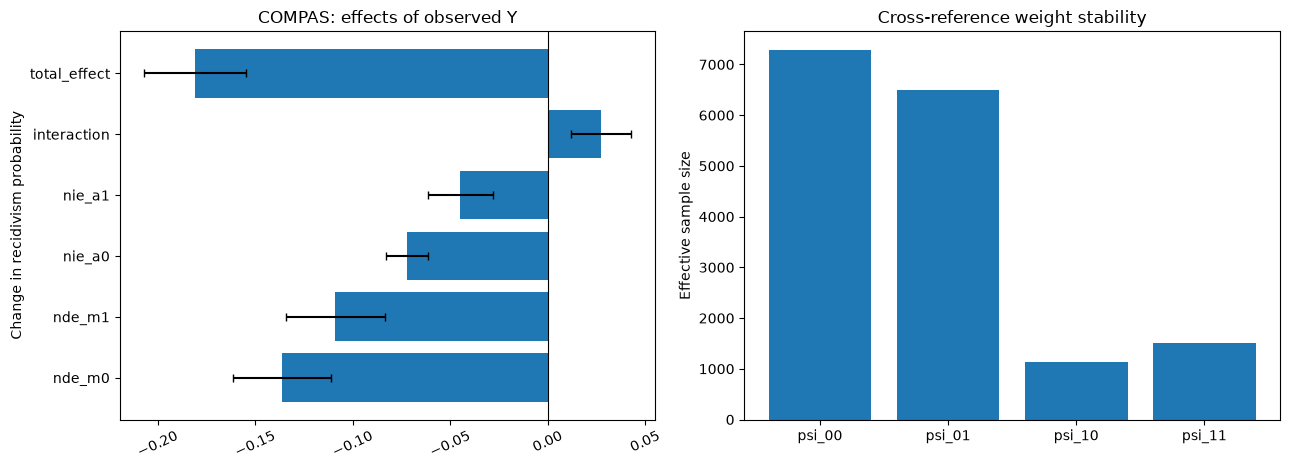

In [13]:
compas_path = REPO_ROOT / 'data' / 'compas' / 'cox-violent-parsed.csv'
compas_dataset = prepare_compas(compas_path)
compas = make_compas_workflow_data(compas_dataset)['assessment']
display(pd.Series(compas_dataset['provenance']['cohort_audit']['counts'], name='rows').to_frame())
print(f"COMPAS complete-case assessment cohort: {len(compas['data']):,}")
compas_result = assess(
    'COMPAS', compas['data'], compas['mediators'], compas['confounders'],
    'Change in recidivism probability', **tuned_options('COMPAS'),
)

## Reddit


,value
counts,"{'source_rows': 436132, 'eligible_rows': 43613..."
excluded_ineligible,0
sample_size,None
sampling_random_state,None


Reddit assessment cohort: 436,132
Reddit: outcome=linear_with_interactions, P(A|C)=logistic, P(A|M,C)=logistic, reduction=pca70


,dataset,effect,estimate,standard_error,ci_low,ci_high
0,Reddit,nde_m0,0.1287,0.0047,0.1194,0.1379
1,Reddit,nde_m1,0.1084,0.0039,0.1008,0.1160
2,Reddit,nie_a0,-0.0751,0.0023,-0.0796,-0.0706
3,Reddit,nie_a1,-0.0954,0.0028,-0.1009,-0.0898
4,Reddit,interaction,-0.0203,0.0033,-0.0268,-0.0137
5,Reddit,total_effect,0.0333,0.0038,0.0258,0.0408


,dataset,nested_mean,clip,propensity_c_min,propensity_c_max,propensity_mc_min,propensity_mc_max,fraction_propensity_c_clipped,fraction_propensity_mc_clipped,max_absolute_weight,...,effective_sample_size,propensity_c_roc_auc,propensity_c_brier_score,propensity_mc_roc_auc,propensity_mc_brier_score,outcome_r2,outcome_rmse,outcome_mae,mediator_dimensions_by_fold,mediator_explained_variance_by_fold
0,Reddit,psi_00,0.01,0.555685,0.555686,0.032312,0.967397,0.0,0.0,2.250663,...,193776.999999,0.499997,0.246898,0.707173,0.21598,0.094826,1.171908,0.869493,"(60, 60, 60, 60, 60)","(0.7012216448783875, 0.7010790109634399, 0.701..."
1,Reddit,psi_01,0.01,0.555685,0.555686,0.032312,0.967397,0.0,0.0,33.933384,...,115964.36854,0.499997,0.246898,0.707173,0.21598,0.094826,1.171908,0.869493,"(60, 60, 60, 60, 60)","(0.7012216448783875, 0.7010790109634399, 0.701..."
2,Reddit,psi_10,0.01,0.555685,0.555686,0.032312,0.967397,0.0,0.0,57.155994,...,125936.716139,0.499997,0.246898,0.707173,0.21598,0.094826,1.171908,0.869493,"(60, 60, 60, 60, 60)","(0.7012216448783875, 0.7010790109634399, 0.701..."
3,Reddit,psi_11,0.01,0.555685,0.555686,0.032312,0.967397,0.0,0.0,1.799581,...,242355.0,0.499997,0.246898,0.707173,0.21598,0.094826,1.171908,0.869493,"(60, 60, 60, 60, 60)","(0.7012216448783875, 0.7010790109634399, 0.701..."


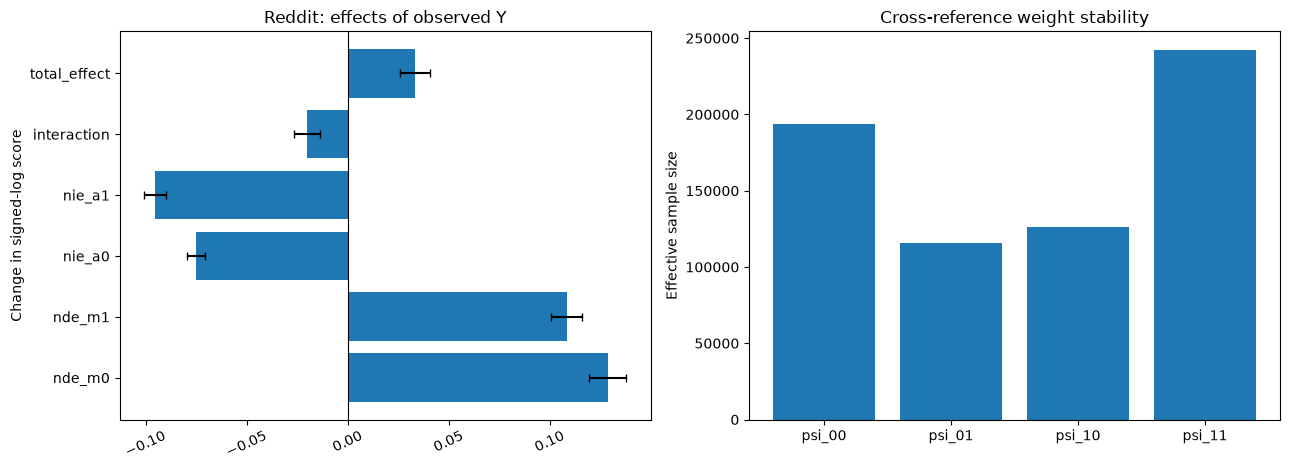

In [14]:
reddit_dataset = prepare_reddit(
    REPO_ROOT / 'data' / 'reddit' / '2018.json',
    REPO_ROOT / 'data' / 'reddit' / '2018_paraphrase_multilingual_minilm_l12_v2_embeddings.npy',
)
reddit = make_assessment_data(reddit_dataset)
display(pd.Series(reddit_dataset['provenance']['cohort_audit'], name='value').to_frame())
print(f"Reddit assessment cohort: {len(reddit['data']):,}")
reddit_result = assess(
    'Reddit', reddit['data'], reddit['mediators'], reddit['confounders'],
    'Change in signed-log score', **tuned_options('Reddit'),
)

## SCUT


,value
label_rows,5500
official_train_rows,3300
official_test_rows,2200
analysis_rows,5500
embedding_failures,()


SCUT assessment cohort: 5,500
SCUT sensitive attribute: A=0 male, A=1 female
SCUT: outcome=linear_with_interactions, P(A|C)=logistic, P(A|M,C)=logistic, reduction=pca70


,dataset,effect,estimate,standard_error,ci_low,ci_high
0,SCUT,nde_m0,0.3392,0.0224,0.2953,0.3831
1,SCUT,nde_m1,0.0359,0.0182,0.0003,0.0715
2,SCUT,nie_a0,0.1369,0.0166,0.1044,0.1694
3,SCUT,nie_a1,-0.1664,0.0209,-0.2074,-0.1255
4,SCUT,interaction,-0.3033,0.0233,-0.3490,-0.2576
5,SCUT,total_effect,0.1728,0.0184,0.1367,0.2088


,dataset,nested_mean,clip,propensity_c_min,propensity_c_max,propensity_mc_min,propensity_mc_max,fraction_propensity_c_clipped,fraction_propensity_mc_clipped,max_absolute_weight,...,effective_sample_size,propensity_c_roc_auc,propensity_c_brier_score,propensity_mc_roc_auc,propensity_mc_brier_score,outcome_r2,outcome_rmse,outcome_mae,mediator_dimensions_by_fold,mediator_explained_variance_by_fold
0,SCUT,psi_00,0.01,0.491407,0.511524,0.010904,0.99,0.0,0.000182,2.047184,...,2749.720676,0.477737,0.250227,0.881971,0.142428,0.601238,0.434487,0.334886,"(139, 139, 139, 139, 139)","(0.7019823789596558, 0.7005742788314819, 0.702..."
1,SCUT,psi_01,0.01,0.491407,0.511524,0.010904,0.99,0.0,0.000182,54.856005,...,624.18251,0.477737,0.250227,0.881971,0.142428,0.601238,0.434487,0.334886,"(139, 139, 139, 139, 139)","(0.7019823789596558, 0.7005742788314819, 0.702..."
2,SCUT,psi_10,0.01,0.491407,0.511524,0.010904,0.99,0.0,0.000182,110.204705,...,531.903329,0.477737,0.250227,0.881971,0.142428,0.601238,0.434487,0.334886,"(139, 139, 139, 139, 139)","(0.7019823789596558, 0.7005742788314819, 0.702..."
3,SCUT,psi_11,0.01,0.491407,0.511524,0.010904,0.99,0.0,0.000182,2.034975,...,2749.730433,0.477737,0.250227,0.881971,0.142428,0.601238,0.434487,0.334886,"(139, 139, 139, 139, 139)","(0.7019823789596558, 0.7005742788314819, 0.702..."


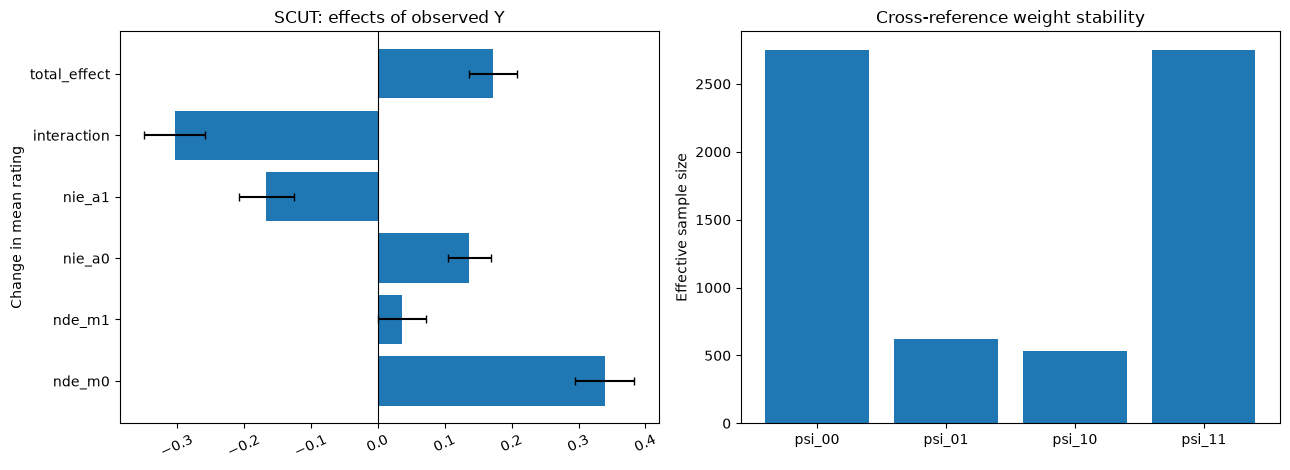

In [15]:
scut_dataset = prepare_scut(REPO_ROOT / 'data' / 'SCUT-FBP5500_v2')
scut = make_assessment_data(scut_dataset)
display(pd.Series(scut_dataset['provenance']['cohort_audit'], name='value').to_frame())
print(f"SCUT assessment cohort: {len(scut['data']):,}")
print('SCUT sensitive attribute: A=0 male, A=1 female')
scut_result = assess(
    'SCUT', scut['data'], scut['mediators'], scut['confounders'],
    'Change in mean rating', **tuned_options('SCUT'),
)

## Four-dataset summary

In [ ]:
all_effects = pd.concat([effect_table(result, dataset) for dataset, result in assessments.items()], ignore_index=True)
all_diagnostics = pd.concat([diagnostic_table(result, dataset) for dataset, result in assessments.items()], ignore_index=True)

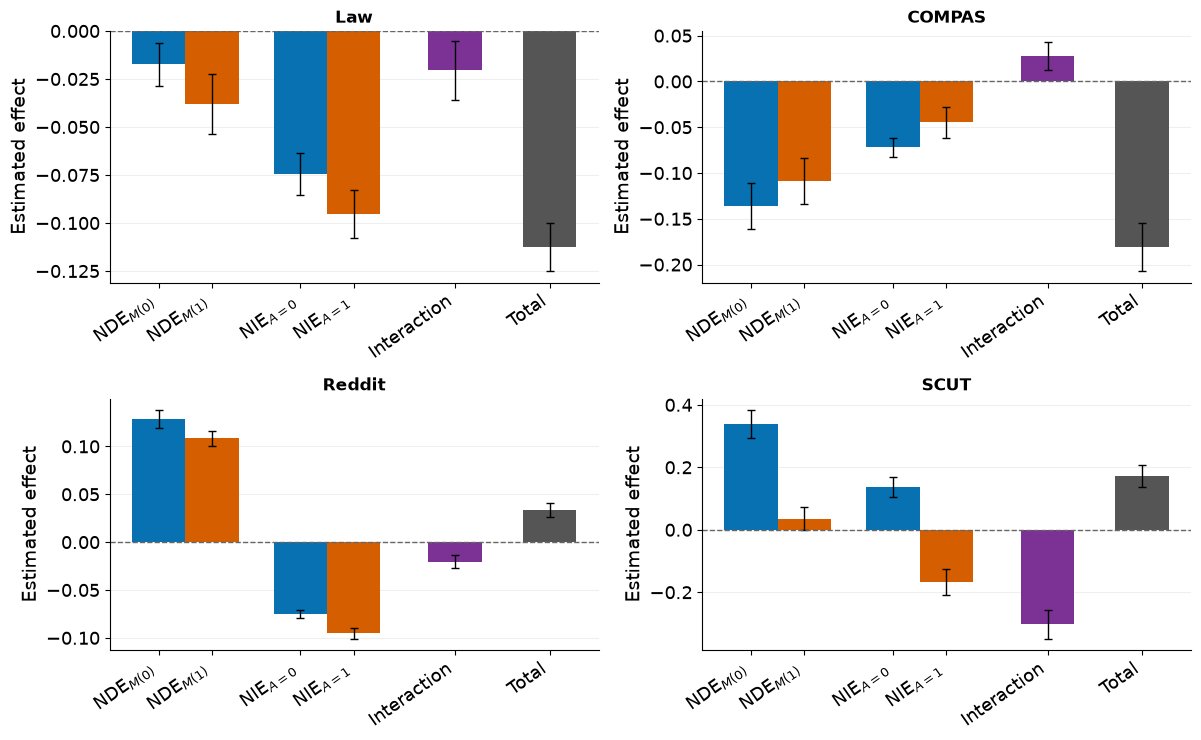

In [17]:
fig, axes = plot_real_data_effects(all_effects)
plt.show()

## Minimal real-data robustness checks

Each check changes exactly one component of the primary specification. The nested model remains linear throughout. All specifications use five-fold cross-fitting and are compared on the same observations within a dataset. Law and COMPAS receive an outcome-model and a propensity-model check. SCUT and Reddit additionally receive PCA 60%, PCA 90%, and PFI 20% checks. The HGB propensity check changes only `P(A|M,C)`; `P(A|C)` remains logistic. Model selection never uses the magnitude or significance of a causal-effect estimate.

In [18]:
import warnings
import numpy as np

RUN_MINIMAL_ROBUSTNESS = True
ROBUSTNESS_REDDIT_MAX_SAMPLES = 500_000
BASE_CHECKS = {
    'primary': 'Primary',
    'outcome_alternative': 'Outcome alternative',
    'propensity_mc_hgb': 'HGB for P(A|M,C)',
}
REDUCTION_CHECKS = {
    'pca60': 'PCA 60%',
    'pca90': 'PCA 90%',
    'pfi20': 'PFI 20%',
}

robustness_data = {
    'Law': law, 'COMPAS': compas, 'SCUT': scut,
    'Reddit': {**reddit, 'data': reproducible_sample(
        reddit['data'], reddit['protected_attribute'],
        ROBUSTNESS_REDDIT_MAX_SAMPLES, random_state=RANDOM_STATE,
    )},
}
pd.DataFrame([
    {'dataset': dataset, 'robustness_n': len(value['data'])}
    for dataset, value in robustness_data.items()
] )

,dataset,robustness_n
0,Law,20970
1,COMPAS,8899
2,SCUT,5500
3,Reddit,436132


In [19]:
robustness_rows = []
if RUN_MINIMAL_ROBUSTNESS:
    for dataset, assessment in robustness_data.items():
        config = load_tuned_config(dataset, TUNED_CONFIG_PATH)
        checks = dict(BASE_CHECKS)
        if dataset in ('SCUT', 'Reddit'):
            checks.update(REDUCTION_CHECKS)
        for check, label in checks.items():
            print(f'{dataset}: {label}')
            with warnings.catch_warnings():
                warnings.simplefilter('always', RuntimeWarning)
                result = estimate_reference_specific_effects(
                    assessment['data'], assessment['outcome'],
                    assessment['protected_attribute'], assessment['mediators'],
                    assessment['confounders'], **DR_OPTIONS,
                    **make_robustness_options(config, check),
                )
            robustness_rows.append(
                robustness_row(dataset, label, check, assessment, config, result)
            )

robustness_results = pd.DataFrame(robustness_rows)

Law: Primary
Law: Outcome alternative
Law: HGB for P(A|M,C)
COMPAS: Primary
COMPAS: Outcome alternative
COMPAS: HGB for P(A|M,C)


/Users/282066/Documents/PHD/Distribution_detection/non-additivity-in-causal-fairness/src/estimate_effects/estimation.py:151: RuntimeWarning: More than 5% of propensity estimates were clipped; inspect overlap.
  warnings.warn("More than 5% of propensity estimates were clipped; inspect overlap.", RuntimeWarning)
/Users/282066/Documents/PHD/Distribution_detection/non-additivity-in-causal-fairness/src/estimate_effects/estimation.py:151: RuntimeWarning: More than 5% of propensity estimates were clipped; inspect overlap.
  warnings.warn("More than 5% of propensity estimates were clipped; inspect overlap.", RuntimeWarning)
/Users/282066/Documents/PHD/Distribution_detection/non-additivity-in-causal-fairness/src/estimate_effects/estimation.py:151: RuntimeWarning: More than 5% of propensity estimates were clipped; inspect overlap.
  warnings.warn("More than 5% of propensity estimates were clipped; inspect overlap.", RuntimeWarning)
/Users/282066/Documents/PHD/Distribution_detection/non-additivit

SCUT: Primary
SCUT: Outcome alternative
SCUT: HGB for P(A|M,C)
SCUT: PCA 60%
SCUT: PCA 90%
SCUT: PFI 20%
Reddit: Primary
Reddit: Outcome alternative
Reddit: HGB for P(A|M,C)
Reddit: PCA 60%
Reddit: PCA 90%
Reddit: PFI 20%


In [20]:
def ci_conclusion(row, effect='interaction'):
    low, high = row[f'{effect}_ci_low'], row[f'{effect}_ci_high']
    return 'positive' if low > 0 else 'negative' if high < 0 else 'includes zero'


if not robustness_results.empty:
    robustness_results['interaction_direction'] = np.sign(
        robustness_results['interaction_estimate']
    ).map({-1: 'negative', 0: 'zero', 1: 'positive'})
    robustness_results['interaction_ci_conclusion'] = robustness_results.apply(
        ci_conclusion, axis=1
    )
    primary = robustness_results[robustness_results['check'] == 'primary'].set_index('dataset')
    robustness_results['interaction_change_from_primary'] = robustness_results.apply(
        lambda row: (
            row['interaction_estimate']
            - primary.loc[row['dataset'], 'interaction_estimate']
        ), axis=1,
    )
    robustness_results['min_ess_percent'] = (
        100 * robustness_results['min_ess'] / robustness_results['n']
    )
    robustness_results['max_clipping_percent'] = (
        100 * robustness_results['max_clipping']
    )
    robustness_results['same_primary_conclusion'] = robustness_results.apply(
        lambda row: (
            row['interaction_direction'] == primary.loc[row['dataset'], 'interaction_direction']
            and row['interaction_ci_conclusion']
            == primary.loc[row['dataset'], 'interaction_ci_conclusion']
        ), axis=1,
    )
    robustness_results.loc[robustness_results['check'] == 'primary',
                           'same_primary_conclusion'] = True

    robustness_path = REPO_ROOT / 'results' / 'assessment' / 'minimal_real_data_robustness.csv'
    robustness_path.parent.mkdir(parents=True, exist_ok=True)
    robustness_results.to_csv(robustness_path, index=False)

    appendix_table = robustness_results[[
        'dataset', 'id', 'specification', 'outcome_model',
        'propensity_model', 'reduction', 'n', 'input_dim',
        'reduced_dim_min', 'reduced_dim_max', 'interaction_estimate',
        'interaction_ci_low', 'interaction_ci_high', 'same_primary_conclusion',
        'interaction_change_from_primary', 'outcome_loss_name', 'outcome_loss',
        'propensity_mc_brier_score', 'min_ess', 'min_ess_percent',
        'max_clipping', 'max_clipping_percent',
        'max_weight_p95', 'max_weight_p99', 'max_absolute_weight',
    ]].copy()
    display(appendix_table.round(4))
    print(f'Saved complete results to {robustness_path.relative_to(REPO_ROOT)}')

,dataset,id,specification,outcome_model,propensity_model,reduction,n,input_dim,reduced_dim_min,reduced_dim_max,...,outcome_loss_name,outcome_loss,propensity_mc_brier_score,min_ess,min_ess_percent,max_clipping,max_clipping_percent,max_weight_p95,max_weight_p99,max_absolute_weight
0,Law,LAW-1,Primary,Logistic + A interactions,Logistic,None,20970,6,6,6,...,log_loss,0.1523,0.0970,697.3290,3.3254,0.0340,3.4001,7.0597,29.9274,273.6469
1,Law,LAW-2,Outcome alternative,HGB + A interactions,Logistic,None,20970,6,6,6,...,log_loss,0.1561,0.0970,697.3290,3.3254,0.0340,3.4001,7.0597,29.9274,273.6469
2,Law,LAW-3,"HGB for P(A|M,C)",Logistic + A interactions,Logistic C; HGB MC,None,20970,6,6,6,...,log_loss,0.1523,0.0922,1029.7793,4.9107,0.0001,0.0143,7.0597,24.4230,116.7127
3,COMPAS,COMPAS-1,Primary,HGB + A interactions,Logistic,None,8899,5,15,16,...,log_loss,0.5635,0.1426,1137.5342,12.7827,0.0042,0.4158,6.6656,10.3586,46.0958
4,COMPAS,COMPAS-2,Outcome alternative,Logistic + A interactions,Logistic,None,8899,5,15,16,...,log_loss,0.6209,0.1426,1137.5342,12.7827,0.0042,0.4158,6.6656,10.3586,46.0958
5,COMPAS,COMPAS-3,"HGB for P(A|M,C)",HGB + A interactions,Logistic C; HGB MC,None,8899,5,15,16,...,log_loss,0.5635,0.1286,347.7317,3.9075,0.0798,7.9784,6.6656,13.8347,133.6397
6,SCUT,SCUT-1,Primary,Linear + A interactions,Logistic,PCA 70%,5500,512,139,139,...,rmse,0.4345,0.1424,531.9033,9.6710,0.0002,0.0182,3.3951,9.0061,110.2047
7,SCUT,SCUT-2,Outcome alternative,HGB + A interactions,Logistic,PCA 70%,5500,512,139,139,...,rmse,0.4475,0.1424,531.9033,9.6710,0.0002,0.0182,3.3951,9.0061,110.2047
8,SCUT,SCUT-3,"HGB for P(A|M,C)",Linear + A interactions,Logistic C; HGB MC,PCA 70%,5500,512,139,139,...,rmse,0.4345,0.1247,400.4384,7.2807,0.0182,1.8182,3.6370,11.0852,63.6224
9,SCUT,SCUT-4,PCA 60%,Linear + A interactions,Logistic,PCA 60%,5500,512,104,105,...,rmse,0.4486,0.1489,594.6119,10.8111,0.0004,0.0364,3.6018,9.1668,59.6882


Saved complete results to results/assessment/minimal_real_data_robustness.csv
